In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
from sklearn.preprocessing import StandardScaler,LabelEncoder,OneHotEncoder,OrdinalEncoder
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
import pickle
from sklearn.pipeline import Pipeline

In [ ]:
data=pd.read_csv("/content/loan_approval_dataset.csv")

In [ ]:
data.head()

,CustomerID,Age,AnnualIncome,CreditScore,EmploymentStatus,LoanAmount,ExistingDebt,PastDefault,LoanApproved
0,1001,59,127450,714,Unemployed,3822,Medium,No,Yes
1,1002,49,60818,836,Employed,20327,Medium,No,Yes
2,1003,35,65525,589,Employed,9150,Medium,Yes,No
3,1004,63,39830,763,Self-Employed,7425,Low,No,Yes
4,1005,28,37429,592,Employed,19032,High,No,No


In [ ]:
data.tail()

,CustomerID,Age,AnnualIncome,CreditScore,EmploymentStatus,LoanAmount,ExistingDebt,PastDefault,LoanApproved
295,1296,27,32161,780,Self-Employed,27578,Medium,No,Yes
296,1297,23,117532,694,Unemployed,31831,High,No,Yes
297,1298,37,112658,694,Unemployed,10906,Low,No,Yes
298,1299,53,143633,654,Employed,10287,Low,No,Yes
299,1300,32,120386,592,Employed,36660,Low,No,Yes


In [ ]:
data.shape

(300, 9)

In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   CustomerID        300 non-null    int64 
 1   Age               300 non-null    int64 
 2   AnnualIncome      300 non-null    int64 
 3   CreditScore       300 non-null    int64 
 4   EmploymentStatus  300 non-null    object
 5   LoanAmount        300 non-null    int64 
 6   ExistingDebt      300 non-null    object
 7   PastDefault       300 non-null    object
 8   LoanApproved      300 non-null    object
dtypes: int64(5), object(4)
memory usage: 21.2+ KB


In [ ]:
data.describe()

,CustomerID,Age,AnnualIncome,CreditScore,LoanAmount
count,300.000000,300.000000,300.000000,300.000000,300.00000
mean,1150.500000,42.696667,86003.696667,675.256667,26373.32000
std,86.746758,13.048328,36989.089364,96.848798,13012.29719
min,1001.000000,21.000000,20301.000000,500.000000,3060.00000
25%,1075.750000,31.000000,55042.250000,594.750000,15669.75000
50%,1150.500000,44.000000,87621.000000,676.500000,27042.50000
75%,1225.250000,54.000000,117613.000000,751.000000,37199.75000
max,1300.000000,64.000000,149307.000000,847.000000,49828.00000


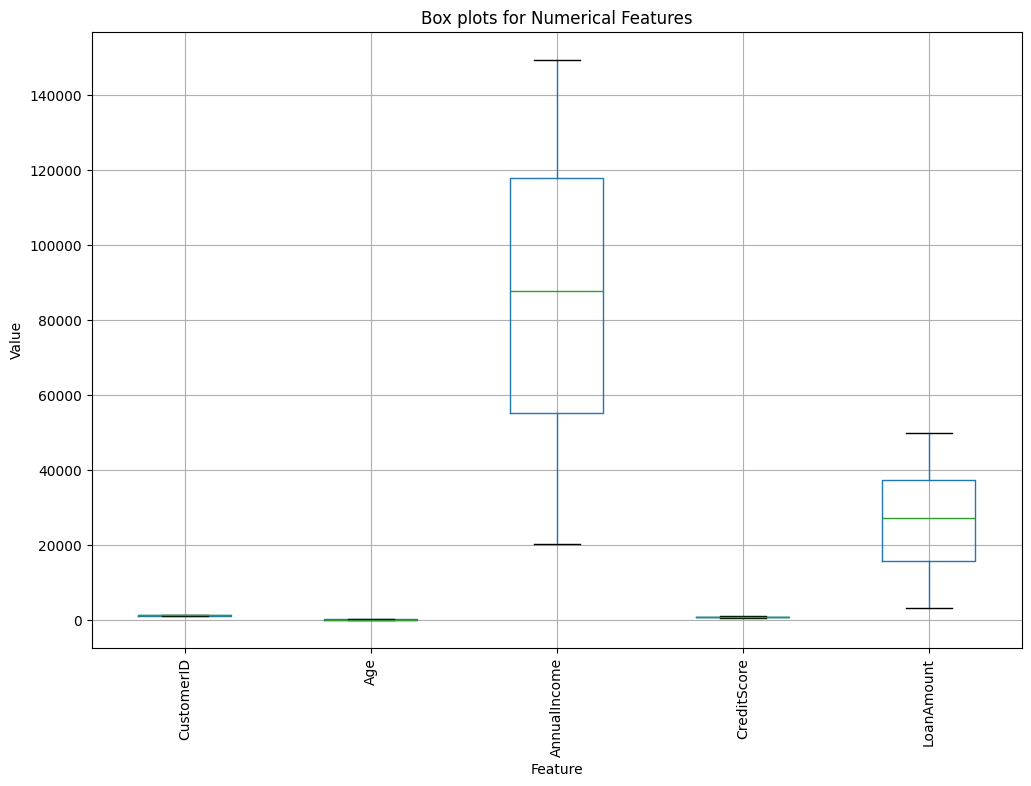

In [ ]:
numerical_cols = data.select_dtypes(include=['int','float']).columns
plt.figure(figsize=(12, 8))
data[numerical_cols].boxplot()
plt.xticks(rotation=90)
plt.title('Box plots for Numerical Features')
plt.ylabel('Value')
plt.xlabel('Feature')
plt.show()

<Axes: >

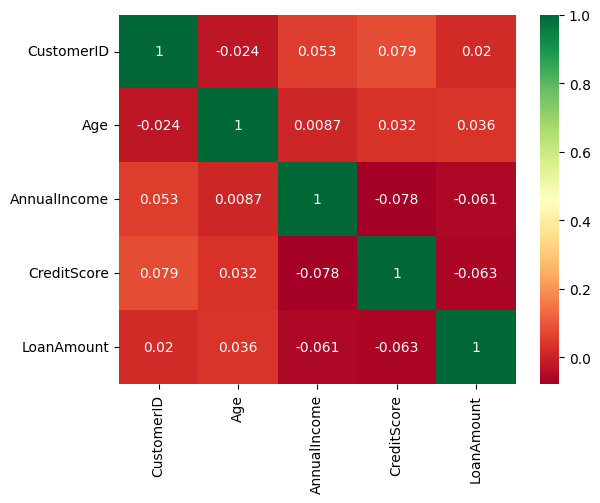

In [ ]:

sns.heatmap(data.select_dtypes(include=['int','float']).corr(),cmap="RdYlGn",annot=True)

In [ ]:
np.where(data.select_dtypes(include=['int', 'float']).corr()>0.9)

(array([0, 1, 2, 3, 4]), array([0, 1, 2, 3, 4]))

In [ ]:
data.columns

Index(['CustomerID', 'Age', 'AnnualIncome', 'CreditScore', 'EmploymentStatus',
       'LoanAmount', 'ExistingDebt', 'PastDefault', 'LoanApproved'],
      dtype='object')

In [ ]:
x = data[["CustomerID", "Age", "AnnualIncome", "CreditScore", "EmploymentStatus",
       "LoanAmount"]]
y = data["LoanApproved"].map({"No": 0, "Yes": 1})

In [ ]:
y

,LoanApproved
0,1
1,1
2,0
3,1
4,0
...,...
295,1
296,1
297,1
298,1


In [ ]:
from sklearn.model_selection import train_test_split

In [ ]:
# Spliting the data into train and test
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=42)

In [ ]:
# Initialize the SMOTE (Synthetic Minority Over-sampling Technique) object into variable
from imblearn.over_sampling import SMOTE
smote=SMOTE()

In [ ]:
x_train["EmploymentStatus"] = x_train["EmploymentStatus"].map({
    "Self-Employed": 1,
    "Employed": 2,
    "Unemployed": 0
})

In [ ]:
x_train_smote,y_train_smote=smote.fit_resample(x_train,y_train)

In [ ]:
from sklearn.tree import DecisionTreeClassifier
dt=DecisionTreeClassifier()
dt.fit(x_train_smote,y_train_smote)

DecisionTreeClassifier()

In [ ]:
mapping = {
    "Self-Employed": 1,
    "Employed": 2,
    "Unemployed": 0
}

x_train["EmploymentStatus"] = x_train["EmploymentStatus"].map(mapping)
x_test["EmploymentStatus"] = x_test["EmploymentStatus"].map(mapping)

In [ ]:
from sklearn.metrics import accuracy_score
y_predict=dt.predict(x_test)
acc=accuracy_score(y_test,y_predict)
acc

0.7166666666666667

In [ ]:
from sklearn.metrics import f1_score
y_predict=dt.predict(x_test)
acc=accuracy_score(y_test,y_predict)
acc

0.7166666666666667

In [ ]:
#creating dictionary--> key value pair of hyperparameters having key as parameter and values as its values
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import RandomizedSearchCV

params = {
    "criterion": ("gini", "entropy"),
    "splitter": ("best", "random"),
    "max_depth": list(range(1, 10)),
    "min_samples_split": [2, 3, 4, 5, 6, 7],
    "min_samples_leaf": list(range(1, 10))
}

tree_clf = DecisionTreeClassifier()

tree_cv = RandomizedSearchCV(
    tree_clf,
    params,
    scoring="f1",
    n_jobs=-1,
    verbose=2,
    cv=5
)

tree_cv.fit(x_train, y_train)

best_params = tree_cv.best_params_
print(f"Best parameters: {best_params}")

Fitting 5 folds for each of 10 candidates, totalling 50 fits
Best parameters: {'splitter': 'random', 'min_samples_split': 7, 'min_samples_leaf': 7, 'max_depth': 3, 'criterion': 'gini'}


In [ ]:
# passing best parameter to decision tree
dt1=DecisionTreeClassifier(criterion='gini',max_depth=3,min_samples_leaf= 4,min_samples_split=2,splitter='best')

In [ ]:
dt1 = DecisionTreeClassifier(**best_params)

dt1.fit(x_train, y_train)

DecisionTreeClassifier(max_depth=3, min_samples_leaf=7, min_samples_split=7,
                       splitter='random')

In [ ]:
y_pre=dt1.predict(x_test)
y_pre

array([1, 0, 1, 1, 1, 0, 1, 1, 1, 0, 1, 0, 1, 1, 0, 0, 1, 1, 0, 0, 0, 1,
       1, 1, 1, 1, 0, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1])

In [ ]:
accuracy_score(y_test,y_pre)

0.7333333333333333

In [ ]:
f1_score(y_test,y_pre)

0.8333333333333334